<h1><center>Practice Activity · Week 3</center></h1>
<b><h2><center>Healthcare Case Study: Stroke Risk Analysis</center></h2></b>
<center><i>AI for Creativity · Exploratory Data Analysis · Independent practice (not graded)</i></center>

### **Context**

According to the World Health Organization, stroke is the 2nd leading cause of death globally. A stroke happens when the blood supply to part of the brain is blocked or a blood vessel bursts. Many risk factors, such as high blood pressure, heart disease, high blood glucose, body weight and smoking, can be measured and managed. Understanding who is most at risk helps hospitals plan screening and prevention campaigns.

### **Objective**

You have been hired as a **Data Analyst** by a hospital network. The public health team has shared a dataset of patient records and asked you to explore it and answer one question:

> **Which patient characteristics are linked to a higher chance of having a stroke?**

You will load and clean the data, produce a statistical summary, create visualizations, and write a short report for a non-technical audience.

### **Key Questions**
1. What does a typical patient in this dataset look like (age, glucose, BMI)?
2. How many patients had a stroke, and is the dataset balanced?
3. How do age, average glucose level and BMI differ between patients who had a stroke and those who did not?
4. Are hypertension, heart disease and smoking status linked to stroke?
5. What would you recommend to the public health team?

### **Dataset**

**Stroke Prediction Dataset** by fedesoriano on Kaggle: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

**How to download it**
1. Sign in to (or create) a free account at **kaggle.com**.
2. Open the dataset link above and click **Download**. You get a zip file.
3. Unzip it on your computer. You will find **healthcare-dataset-stroke-data.csv**.
4. In Colab, click the 📁 **Files** icon on the left, then the **Upload** icon, and upload the CSV. (Or put it in your Google Drive and mount the drive, as we did in the MovieLens case study.)

### **Data Dictionary**

| Column | Description |
|---|---|
| id | Unique patient identifier |
| gender | Male, Female or Other |
| age | Age of the patient in years |
| hypertension | 1 = has high blood pressure, 0 = does not |
| heart_disease | 1 = has a heart disease, 0 = does not |
| ever_married | Yes or No |
| work_type | children, Govt_job, Never_worked, Private or Self-employed |
| Residence_type | Rural or Urban |
| avg_glucose_level | Average glucose level in the blood (mg/dL) |
| bmi | Body mass index |
| smoking_status | formerly smoked, never smoked, smokes or Unknown |
| stroke | **Target:** 1 = the patient had a stroke, 0 = did not |

*Ethics note: this is anonymised data shared for learning. Treat health data with care, and never try to identify individuals.*

## **Part A · Load and understand the data**

#### **A1. Import the libraries**
Run the cell below.

In [1]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

#### **A2. Load the dataset**
Read **healthcare-dataset-stroke-data.csv** into a dataframe called `data`, then make a copy called `df` to work on.

*Hint:* `pd.read_csv()` and `.copy()`

In [2]:
# Load the CSV file
data = pd.read_csv("healthcare-dataset-stroke-data.csv")

# Make a copy to work on
df = data.copy()

#### **A3. First look**
Show the first 5 rows and the last 5 rows.

*Hint:* `.head()` and `.tail()`

In [3]:
# First 5 rows
df.head()


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [4]:
# Last 5 rows
df.tail()


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


#### **A4. Shape and data types**
How many rows and columns are there? What is the data type of each column?

*Hint:* `.shape` and `.info()`

In [5]:
# Shape
df.shape


(5110, 12)

In [45]:
# Data types and non-null counts
df.info()


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000
mean,43.226614,0.097456,0.054012,106.147677,28.862035,0.048728
std,22.612647,0.296607,0.226063,45.283560,7.699562,0.215320
min,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,25.000000,0.000000,0.000000,77.245000,23.800000,0.000000
50%,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,61.000000,0.000000,0.000000,114.090000,32.800000,0.000000
max,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


#### **A5. Missing values and duplicates**
Count the missing values in each column and check for duplicate rows.

*Hint:* `.isnull().sum()` and `.duplicated().sum()`

In [7]:
# Missing values per column
df.isnull().sum()


id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [8]:
# Duplicate rows
df.duplicated().sum()


np.int64(0)

#### **A6. Clean the data**
1. The `id` column is only an identifier, so drop it.
2. Fill the missing `bmi` values with the **median** BMI. Why is the median safer than the mean here?
3. Check that no missing values remain.

*Hint:* `.drop(columns=...)` and `.fillna()`

In [16]:
# # Drop the id column
try: 
    df = df.drop(columns="id")
except:
    print("id column already removed")

median = df["bmi"].median()
df["bmi"] = df["bmi"].fillna(median)

df.head()

id column already removed


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## **Part B · Statistical summary**

#### **B1. Summary of the numerical columns**
Produce the statistical summary of the numerical columns.

*Hint:* `.describe().T`

In [19]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,5110.0,43.226614,22.612647,0.08,25.000,45.000,61.00,82.00
hypertension,5110.0,0.097456,0.296607,0.00,0.000,0.000,0.00,1.00
heart_disease,5110.0,0.054012,0.226063,0.00,0.000,0.000,0.00,1.00
avg_glucose_level,5110.0,106.147677,45.283560,55.12,77.245,91.885,114.09,271.74
bmi,5110.0,28.862035,7.699562,10.30,23.800,28.100,32.80,97.60
stroke,5110.0,0.048728,0.215320,0.00,0.000,0.000,0.00,1.00


**Observations:** _write 2 or 3 sentences: what do you see, and what might it mean?_

#### **B2. Summary of the categorical columns**
Produce a summary of the text (categorical) columns.

*Hint:* `.describe(include='object').T`

In [21]:
df.describe(include="str").T

,count,unique,top,freq
gender,5110,3,Female,2994
ever_married,5110,2,Yes,3353
work_type,5110,5,Private,2925
Residence_type,5110,2,Urban,2596
smoking_status,5110,4,never smoked,1892


**Observations:** _write 2 or 3 sentences: what do you see, and what might it mean?_

#### **B3. Value counts**
For `gender`, `work_type` and `smoking_status`, show how many patients fall in each category.

*Hint:* `.value_counts()`

In [25]:
df[["gender", "work_type", "smoking_status"]].value_counts()



gender  work_type      smoking_status 
Female  Private        never smoked       781
Male    Private        never smoked       430
Female  Private        Unknown            373
Male    children       Unknown            326
Female  Private        smokes             313
        children       Unknown            292
        Private        formerly smoked    287
Male    Private        Unknown            267
                       formerly smoked    243
Female  Self-employed  never smoked       237
Male    Private        smokes             230
Female  Govt_job       never smoked       175
        Self-employed  formerly smoked    112
Male    Govt_job       never smoked       107
        Self-employed  formerly smoked     96
                       never smoked        94
Female  Self-employed  Unknown             90
        Govt_job       Unknown             79
                       smokes              73
                       formerly smoked     72
Male    Self-employed  Unknown           

**Observations:** _write 2 or 3 sentences: what do you see, and what might it mean?_

#### **B4. The target**
How many patients had a stroke? What **percentage** is that? Is the dataset balanced?

*Hint:* `.value_counts(normalize=True) * 100`

In [27]:
df["stroke"].value_counts(normalize=True) * 100


stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64

**Observations:** _write 2 or 3 sentences: what do you see, and what might it mean?_

#### **B5. Compare the two groups**
Calculate the **mean** age, avg_glucose_level and bmi for patients **with** and **without** a stroke.

*Hint:* `df.groupby('stroke')[[...]].mean()`

In [28]:
df.groupby("stroke")[["age", "avg_glucose_level", "bmi"]].mean()


,age,avg_glucose_level,bmi
stroke,,,
0,41.971545,104.795513,28.799115
1,67.728193,132.544739,30.090361


**Observations:** _write 2 or 3 sentences: what do you see, and what might it mean?_

## **Part C · Univariate analysis** (one variable at a time)

#### **C1. Helper function**
Run the cell below. It is the same `histogram_boxplot` function from the Uber case study.

In [29]:
# Defining the function for creating boxplot and histogram (same as the Uber case study)
def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize)  # creating the 2 subplots
    sns.boxplot(data=data, x=feature, ax=ax_box2, showmeans=True, color="mediumturquoise")  # star = mean
    if bins:
        sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, color="mediumpurple")
    else:
        sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2, color="mediumpurple")
    ax_hist2.axvline(data[feature].mean(), color="green", linestyle="--")   # mean
    ax_hist2.axvline(data[feature].median(), color="black", linestyle="-")  # median
    plt.show()

#### **C2. Numerical variables**
Use `histogram_boxplot` for **age**, **avg_glucose_level** and **bmi**. Look at the shape, the mean (green) vs median (black) and the outliers.

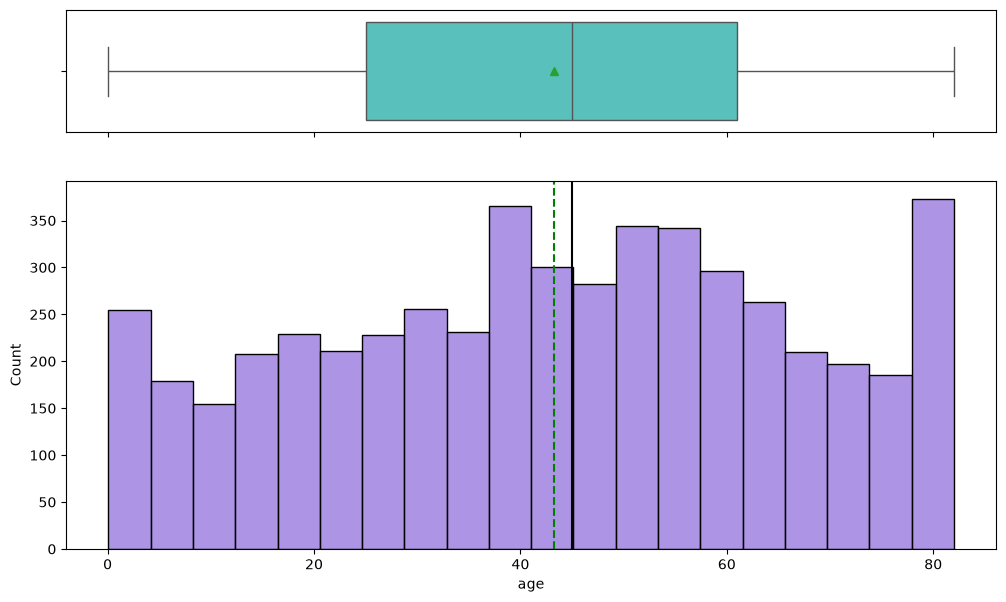

In [32]:
# age
histogram_boxplot(df, "age")


**Observations:** _write 2 or 3 sentences: what do you see, and what might it mean?_

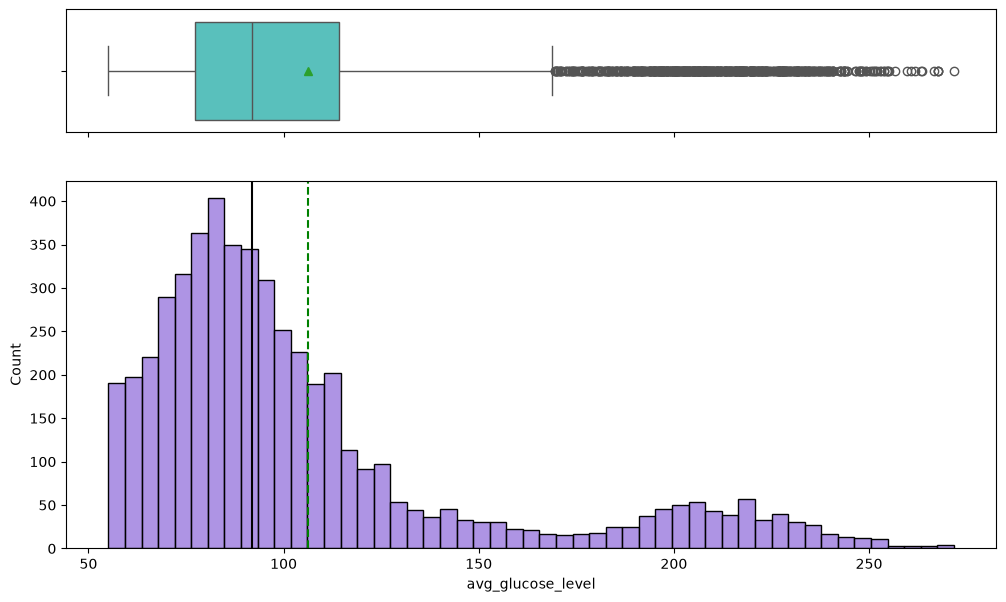

In [33]:
# avg_glucose_level
histogram_boxplot(df, "avg_glucose_level")


**Observations:** _write 2 or 3 sentences: what do you see, and what might it mean?_

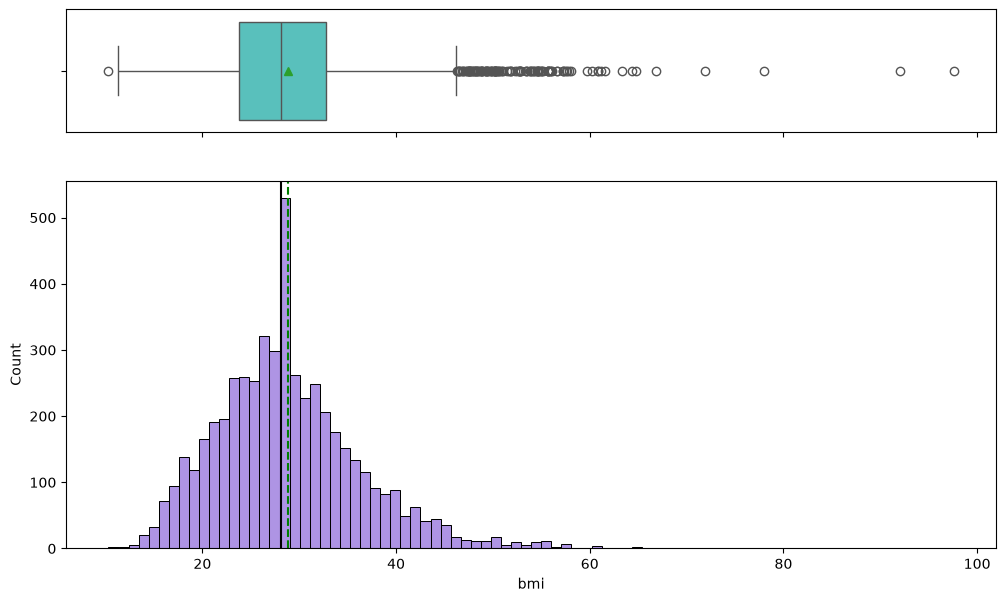

In [34]:
# bmi
histogram_boxplot(df, "bmi")



**Observations:** _write 2 or 3 sentences: what do you see, and what might it mean?_

#### **C3. Categorical variables**
Make a **countplot** for `stroke`, `gender`, `smoking_status` and `work_type`.

*Hint:* `sns.countplot(data=df, x='...')`. Use `plt.xticks(rotation=45)` if labels overlap.

([0, 1], [Text(0, 0, '0'), Text(1, 0, '1')])

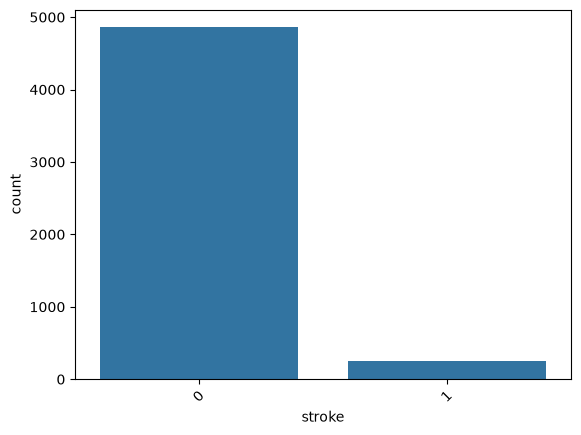

In [46]:
sns.countplot(data=df, x="stroke")
plt.xticks(rotation=45)


**Observations:** _write 2 or 3 sentences: what do you see, and what might it mean?_

## **Part D · Bivariate and multivariate analysis** (relationships)

#### **D1. Correlation heatmap**
Plot a heatmap of the correlation between the numerical columns: age, hypertension, heart_disease, avg_glucose_level, bmi and stroke.

*Hint:* `df[num_var].corr()` and `sns.heatmap(..., annot=True, cmap='Spectral')`

In [14]:
num_var = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']



**Observations:** _write 2 or 3 sentences: what do you see, and what might it mean?_

#### **D2. Age vs stroke**
Make a **boxplot** of age for stroke = 0 and stroke = 1.

*Hint:* `sns.boxplot(data=df, x='stroke', y='age')`

**Observations:** _write 2 or 3 sentences: what do you see, and what might it mean?_

#### **D3. Glucose vs stroke**
Make a **violinplot** of avg_glucose_level for stroke = 0 and stroke = 1.

*Hint:* `sns.violinplot(...)`

**Observations:** _write 2 or 3 sentences: what do you see, and what might it mean?_

#### **D4. Stroke rate by risk factor**
Show the **percentage of patients who had a stroke** for each group of `hypertension`, `heart_disease` and `smoking_status`.

*Hint:* `df.groupby('hypertension')['stroke'].mean() * 100`, then a barplot: `sns.barplot(data=df, x='hypertension', y='stroke')`

**Observations:** _write 2 or 3 sentences: what do you see, and what might it mean?_

#### **D5. Age, glucose and stroke together**
Make a **scatterplot** of age (x) against avg_glucose_level (y), coloured by stroke.

*Hint:* `sns.scatterplot(..., hue='stroke', alpha=0.5)`

**Observations:** _write 2 or 3 sentences: what do you see, and what might it mean?_

#### **D6. Stretch (optional)**
Try one plot of your own choice from the Week 2 notebook: for example `sns.catplot`, `sns.pairplot` or a Plotly chart (`px.histogram`). Explain what it shows.

In [15]:
# Your own plot



**Observations:** _write 2 or 3 sentences: what do you see, and what might it mean?_

## **Part E · Your data analyst summary**

Write a short report (**250 to 400 words**) for the hospital's public health team. They are **not** data experts, so use plain language and refer to your charts.

**Use these headings:**
1. **The data:** how many patients, what was missing, and how you cleaned it.
2. **Key statistics:** typical age, glucose and BMI; the percentage of patients who had a stroke.
3. **Main findings:** which factors are linked to a higher stroke rate? Give numbers (for example, *"X% of patients with hypertension had a stroke, compared with Y% without"*).
4. **Limitations:** what this data **cannot** tell us. *Think about: an imbalanced target, missing BMI values, "Unknown" smoking status, and the difference between a link (correlation) and a cause.*
5. **Recommendations:** two or three actions for the public health team.

_Write your summary here._

---
### **Submission checklist**
- [ ] Every cell runs from top to bottom without errors (**Runtime → Run all**)
- [ ] Every **Observations** cell is filled in
- [ ] Part E summary written (250 to 400 words)
- [ ] File named **YourName_W03_StrokeEDA.ipynb** (for example `GeethaMohan_W03_StrokeEDA.ipynb`)
- [ ] Uploaded to **W03 · Weekly Submission** on Moodle, with your R&D journal entry

In [47]:
import numpy as np
grid = np.zeros((3, 4))
print(grid.shape)


(3, 4)


In [48]:
import numpy as np
arr = np.array([10, 20, 30])
print(arr[arr > 15])

[20 30]
